# Aula 14: Interpolação Polinomial: Lagrange

## Ideia

Dados $n+1$ pontos distintos $(x_0,y_0),\ldots,(x_n,y_n)$, buscamos um polinômio $p_n(x)$ de grau no máximo $n$ tal que

$$p_n(x_i)=y_i,\qquad i=0,\ldots,n.$$

O polinômio pode ser utilizado para estimar valores entre os pontos conhecidos.

## Forma de Lagrange

$$p_n(x)=\sum_{k=0}^{n}y_k L_k(x),$$

em que os polinômios básicos são

$$L_k(x)=\prod_{\substack{j=0\\j\ne k}}^{n}\frac{x-x_j}{x_k-x_j}.$$

Assim, $L_k(x_i)=1$ quando $i=k$ e $L_k(x_i)=0$ quando $i\ne k$.

## Algoritmo: Cálculo de $p_n(t)$

```text
Entrada:
    x = vetor com n+1 nós de interpolação
    y = vetor com n+1 valores correspondentes
    t = ponto em que queremos avaliar o polinômio

p = 0
Para k de 0 até n faça
    L = 1
    Para j de 0 até n faça
        Se j ≠ k então
            L = L * (t - x[j]) / (x[k] - x[j])
        Fim-Se
    Fim-Para
    p = p + y[k] * L
Fim-Para
Retorne p
```

In [3]:
def lagrange(x, y, t):
    """Calcula o polinômio interpolador de Lagrange no ponto t."""
    n = len(x)
    p = 0
    for k in range(n):
        L = 1

        for j in range(n):
            if j != k:
                L = L * (t - x[j]) / (x[k] - x[j])

        p = p + y[k] * L

    return p

In [4]:
import numpy as np
import matplotlib.pyplot as plt

def grafico(x, y, titulo, t=None):
    # Criar pontos para desenhar a curva
    margem = (max(x) - min(x)) * 0.15
    inicio = min(x) - margem
    fim = max(x) + margem

    grade = np.linspace(inicio, fim, 400)

    # Calcular o polinômio em cada ponto
    valores = [lagrange(x, y, ponto) for ponto in grade]

    # Construir o gráfico
    plt.figure(figsize=(8, 4.5))
    plt.plot(grade, valores, label="Polinômio interpolador")
    plt.scatter(x, y, s=60, label="Pontos conhecidos")

    if t is not None:
        valor = lagrange(x, y, t)
        plt.scatter(
            t, valor,
            s=75,
            marker="x",
            label=f"p({t}) = {valor:.4g}"
        )

    plt.title(titulo)
    plt.xlabel("x")
    plt.ylabel("p(x)")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()

## Exemplo: Interpolação linear 

Para dois pontos $(x_0,y_0)$ e $(x_1,y_1)$, temos $n=1$:

$$L_0(x)=\frac{x-x_1}{x_0-x_1},\qquad L_1(x)=\frac{x-x_0}{x_1-x_0}.$$

Portanto,

$$\boxed{p_1(x)=y_0\frac{x-x_1}{x_0-x_1}+y_1\frac{x-x_0}{x_1-x_0}}.$$

Esse é o polinômio da reta que passa pelos dois pontos. Para visualizar, vamos usar os pontos $(-1,4)$ e $(0,1)$, retirados da tabela do exemplo anterior.

p1(x) = 1 - 3x
p1(-0.5) = 2.5
p1(-1) = 4.0
p1(0) = 1.0


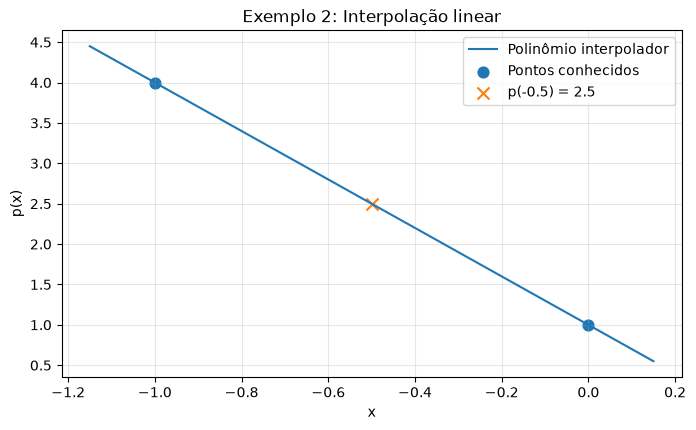

In [5]:
x2 = [-1, 0]
y2 = [4, 1]
print('p1(x) = 1 - 3x')
print('p1(-0.5) =', lagrange(x2, y2, -0.5))
print('p1(-1) =', lagrange(x2, y2, -1))
print('p1(0) =', lagrange(x2, y2, 0))
grafico(x2, y2, 'Exemplo 2: Interpolação linear', t=-0.5)

## Exemplo: Forma de Lagrange 

Usaremos os mesmos três pontos do Exemplo 1:

| $x$ | $-1$ | $0$ | $2$ |
|---|---:|---:|---:|
| $f(x)$ | $4$ | $1$ | $-1$ |

Os polinômios básicos são:

$$L_0(x)=\frac{x(x-2)}3,\qquad L_1(x)=-\frac{(x+1)(x-2)}2,\qquad L_2(x)=\frac{x(x+1)}6.$$

Assim,

$$p_2(x)=4L_0(x)+L_1(x)-L_2(x)$$

$$\boxed{p_2(x)=1-\frac73x+\frac23x^2}.$$

Obtivemos o mesmo polinômio da resolução do sistema linear.

p(-1) = 4 (valor tabelado: 4)
p(0) = 1 (valor tabelado: 1)
p(2) = -1 (valor tabelado: -1)


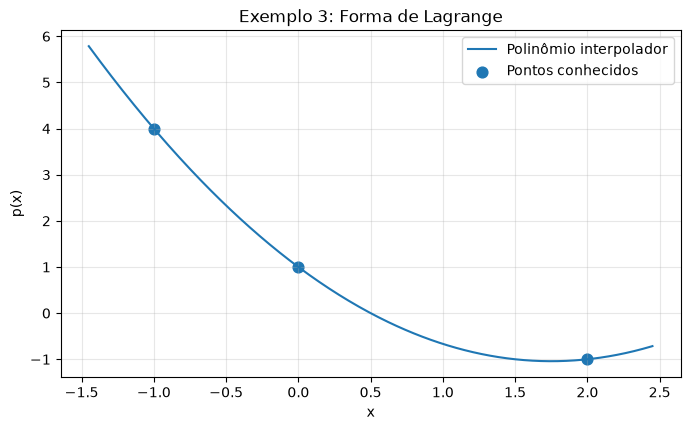

In [4]:
x3 = [-1, 0, 2]
y3 = [4, 1, -1]
for xi, yi in zip(x3, y3):
    print(f'p({xi}) = {lagrange(x3, y3, xi):.4g} (valor tabelado: {yi})')
grafico(x3, y3, 'Exemplo 3: Forma de Lagrange')

## Exercício: Interpolação de Lagrange

Considere os pontos:

| $x$ | $0$ | $1$ | $3$ |
|---|---:|---:|---:|
| $f(x)$ | $2$ | $3$ | $11$ |

1. Determine $L_0(x)$, $L_1(x)$ e $L_2(x)$.
2. Obtenha o polinômio interpolador $p_2(x)$.
3. Verifique as condições de interpolação.
4. Calcule $p_2(2)$.

**Resolução:**

$$L_0(x)=\frac{(x-1)(x-3)}3,\qquad L_1(x)=-\frac{x(x-3)}2,\qquad L_2(x)=\frac{x(x-1)}6.$$

$$p_2(x)=2L_0(x)+3L_1(x)+11L_2(x)=\boxed{x^2+2}.$$

$$p_2(0)=2,\quad p_2(1)=3,\quad p_2(3)=11,\quad \boxed{p_2(2)=6}.$$

p(0) = 2 (esperado: 2)
p(1) = 3 (esperado: 3)
p(3) = 11 (esperado: 11)
p(2) = 6.0


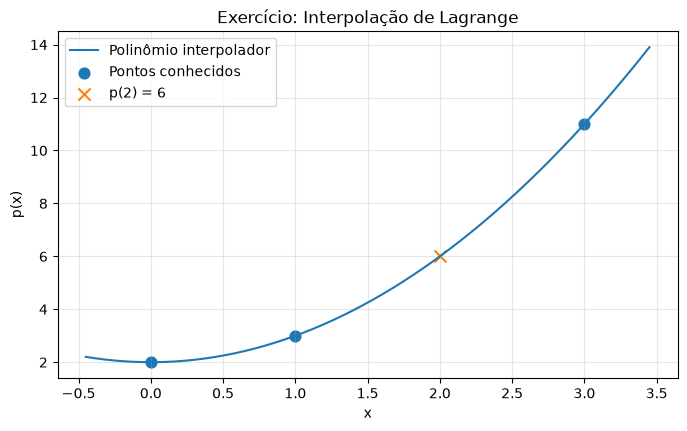

In [5]:
x_ex = [0, 1, 3]
y_ex = [2, 3, 11]
for xi, yi in zip(x_ex, y_ex):
    print(f'p({xi}) = {lagrange(x_ex, y_ex, xi):.4g} (esperado: {yi})')
print('p(2) =', lagrange(x_ex, y_ex, 2))
grafico(x_ex, y_ex, 'Exercício: Interpolação de Lagrange', t=2)

## Exemplo adicional: Interpolação com vários pontos

Agora considere **seis pontos** conhecidos:

| $x$ | $-2$ | $-1$ | $0$ | $1$ | $2$ | $3$ |
|---|---:|---:|---:|---:|---:|---:|
| $f(x)$ | $3$ | $0$ | $1$ | $2$ | $1$ | $4$ |

Com seis nós distintos, existe um único polinômio interpolador de grau **no máximo 5**.

Usamos o mesmo algoritmo de Lagrange, sem precisar montar e resolver um sistema linear. O gráfico mostra como a curva passa exatamente por todos os pontos.

p(0.5) = 1.7421875
Valores nos nós: [3.0, 0.0, 1.0, 2.0, 1.0, 4.0]


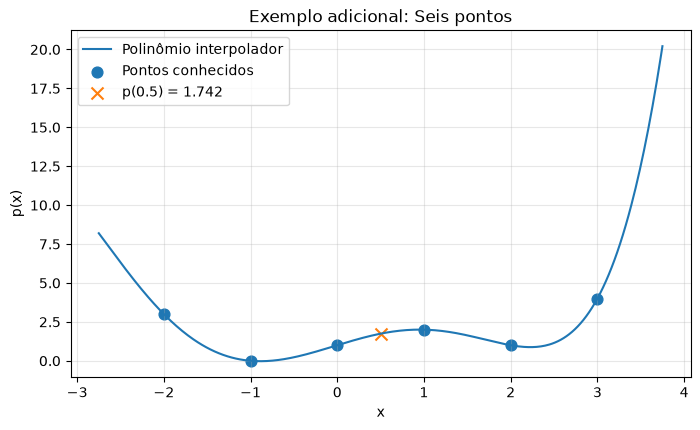

In [7]:
x_varios = [-2, -1, 0, 1, 2, 3]
y_varios = [3, 0, 1, 2, 1, 4]

print('p(0.5) =', lagrange(x_varios, y_varios, 0.5))
print('Valores nos nós:', [lagrange(x_varios, y_varios, t) for t in x_varios])

grafico(x_varios, y_varios, 'Exemplo adicional: Seis pontos', t=0.5)